# 13 · Probabilities and thresholds

[Guide](../README.md) | [Previous](12_Ensembling.ipynb) | [Next](14_Interpretation_and_Error_Analysis.ipynb)

Compare four probability/decision choices and freeze one for the final notebook.

## Data: training, validation, competition test
`train.csv` contains known answers; `test.csv` does not.
Split `train.csv`: 16,000 rows for learning and comparisons; 4,000 validation rows for the final check.
Comparisons below stay inside the training part. `random_state` repeats the split;
`stratify` keeps similar goal/miss proportions. `X` means inputs; `y` means answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

Train: (20000, 20) Test: (6000, 19)


In [3]:
# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

In [4]:
# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

In [5]:
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline
from catboost import CatBoostClassifier

## Continue from the earlier lessons

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |
| Reduction | No PCA |
| Outliers | Add a flag |
| Balancing | Original class counts |
| Model | CatBoost |
| Tuning | Random search |
| Ensemble | Single model |

Only the current choice changes. `clone` copies settings, not fitted knowledge; `step__setting` points to one pipeline setting.

**Incomplete training rows:** `any(axis=1)` finds a row with at least one blank; `~` keeps the opposite rows. Filter `y` too so answers stay aligned.

In [6]:
def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

**Suspected decoys:** test removing jersey color and referee strictness, not every weak-looking input. The same columns are removed at prediction time.

In [7]:
def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

**Form and technique features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [8]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

**Match context features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [9]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

**Environment features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [10]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

In [11]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

In [12]:
def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

In [13]:
def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

## Prepare each training split separately
Fill numbers with a training mean or median; fill categories with the most common value (**mode**).
Scaling puts numbers on similar scales. Encoding turns category names into numbers (Lesson 04).
No filling values, rankings, or sampling decisions are learned from validation rows.

In [14]:
numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

**Pipeline:** run steps in order. `passthrough` skips a step. `FunctionSampler` applies a row-changing function only during fitting; every prediction-time row is kept. Balancing also runs only during fitting.

In [15]:
pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='Logloss', random_seed=42, thread_count=2, verbose=False, allow_writing_files=False)),
])

## Compare on the same three splits
Train on two groups, score the third, and rotate. **F1** balances precision and recall;
**accuracy** counts all correct answers; **ROC-AUC** measures probability ranking.
**F1 spread** shows how much scores change across the three splits.

In [16]:
# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

In [17]:
selected_model = clone(pipeline)

**Calibration:** probabilities should match observed scoring rates.
**Threshold:** the cutoff turning a probability into a goal/miss decision.
A reliable probability does not automatically give the best F1 at a cutoff of 0.5.

| Choice | What it does | Trade-off |
|---|---|---|
| Original probabilities | Keep model probabilities; cutoff 0.5 | Simplest |
| Sigmoid calibration | Fit a smooth probability correction | Less flexible |
| Isotonic calibration | Fit a monotonic correction | Flexible; needs more data |
| Training-selected threshold | Compare cutoffs 0.3–0.7 inside training | Can overfit if chosen on validation answers |

Each correction or threshold is learned inside the outer comparison's training rows.

In [18]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TunedThresholdClassifierCV
models = {
    "Original probabilities": clone(selected_model),
    "Sigmoid calibration": CalibratedClassifierCV(clone(selected_model), method="sigmoid", cv=cv),
    "Isotonic calibration": CalibratedClassifierCV(clone(selected_model), method="isotonic", cv=cv),
    "Training-selected threshold": TunedThresholdClassifierCV(clone(selected_model), scoring="f1", response_method="predict_proba", thresholds=np.linspace(0.3, 0.7, 9), cv=cv),
}

,method,F1,F1 spread,accuracy,ROC-AUC
0,Original probabilities,0.946,0.003,0.952,0.992
3,Training-selected threshold,0.946,0.003,0.952,0.992
2,Isotonic calibration,0.945,0.002,0.951,0.992
1,Sigmoid calibration,0.945,0.003,0.951,0.992


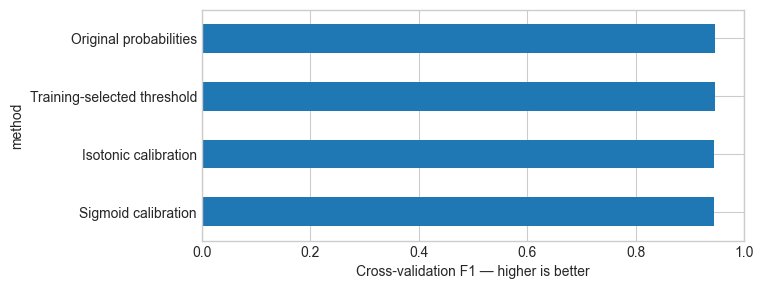

Continue with: Original probabilities


In [19]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

In [20]:
threshold = 0.5
selected_name = results.iloc[0]["method"]
if selected_name == "Training-selected threshold":
    threshold_model = clone(models[selected_name])
    threshold_model.fit(X, y)
    threshold = float(threshold_model.best_threshold_)
print("Threshold to continue:", threshold)

Threshold to continue: 0.5


## Example: what changes for the same unseen kicks?
Fit a small worked example using only its training rows. Compare the original probabilities
with sigmoid calibration; the reliability plot's diagonal means probabilities match observed rates.
This illustration does not change the winner above.

In [21]:
from sklearn.calibration import CalibrationDisplay
X_fit, X_example, y_fit, y_example = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
raw = clone(selected_model).fit(X_fit, y_fit)
calibrated = CalibratedClassifierCV(clone(selected_model), method="sigmoid", cv=3)
calibrated.fit(X_fit, y_fit)
raw_p = raw.predict_proba(X_example)[:, 1]
calibrated_p = calibrated.predict_proba(X_example)[:, 1]
display(pd.DataFrame({"actual": y_example, "original probability": raw_p, "sigmoid probability": calibrated_p}).head())

,actual,original probability,sigmoid probability
8006,0,0.427,0.201
8356,0,0.057,0.019
13894,1,0.997,0.989
14910,1,1.000,0.989
3100,0,0.001,0.012


In [22]:
decisions = pd.DataFrame({"actual": y_example, "goal probability": raw_p})
decisions["cutoff 0.3"] = (raw_p >= 0.3).astype(int)
decisions["cutoff 0.5"] = (raw_p >= 0.5).astype(int)
decisions["cutoff 0.7"] = (raw_p >= 0.7).astype(int)
display(decisions.loc[decisions["goal probability"].between(0.3, 0.7)].head(8))

,actual,goal probability,cutoff 0.3,cutoff 0.5,cutoff 0.7
8006,0,0.427,1,0,0
3716,0,0.477,1,0,0
15925,1,0.619,1,1,0
506,0,0.532,1,1,0
91,1,0.421,1,0,0
7246,0,0.305,1,0,0
9886,1,0.568,1,1,0
8485,0,0.493,1,0,0


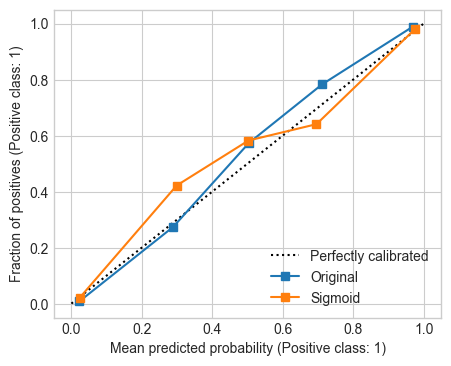

In [23]:
fig, ax = plt.subplots(figsize=(5, 4))
CalibrationDisplay.from_predictions(y_example, raw_p, name="Original", ax=ax)
CalibrationDisplay.from_predictions(y_example, calibrated_p, name="Sigmoid", ax=ax)
plt.show()

**Why the choice?** Select using unseen-row F1 because that is the project metric.
We compare calibration and cutoff tuning as separate candidates, not every possible combination.

**Other alternatives:** use Brier/log loss when probability accuracy matters most; choose a threshold
for recall or error costs when missing goals and falsely predicting goals have different consequences.

## Choice carried into the next lesson

**Probabilities: Original probabilities.** The tested corrections did not improve the project metric; keep the simpler probabilities and cutoff.

This is the best tested choice at this stage, not proof that a small score gap is significant or that every combination has been tried.

The cutoff learned from the training part is **0.50**. Only that fixed value continues.